# Bài 2 (Trang 15-17) – Titanic
Tải `titanic.csv` lên thư mục Files của Colab trước khi chạy.

In [1]:
# ===== Câu 1: Nhập dữ liệu và thống kê thông tin cơ bản của các thuộc tính =====
print("Nguyễn Bình Minh - 6451071047")

# linear algebra
import numpy as np
# data processing
import pandas as pd
# data visualization
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import style
import re
import warnings
warnings.filterwarnings("ignore")

with open('titanic.csv') as f:
    df = pd.read_csv(f, dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

display(df.head(12))
df.info()
display(df.describe())
display(df.describe(include='object'))

Nguyễn Bình Minh - 6451071047


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
5,1,1,"Anderson, Mr. Harry",male,48.0000,0,0,19952,26.5500,E12,S,3,NaN,"New York, NY"
6,1,1,"Andrews, Miss. Kornelia Theodosia",female,63.0000,1,0,13502,77.9583,D7,S,10,NaN,"Hudson, NY"
7,1,0,"Andrews, Mr. Thomas Jr",male,39.0000,0,0,112050,0.0000,A36,S,NaN,NaN,"Belfast, NI"
8,1,1,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",female,53.0000,2,0,11769,51.4792,C101,S,D,NaN,"Bayside, Queens, NY"
9,1,0,"Artagaveytia, Mr. Ramon",male,71.0000,0,0,PC 17609,49.5042,NaN,C,NaN,22.0,"Montevideo, Uruguay"


<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 143.3 KB


,pclass,survived,age,sibsp,parch,fare,body
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200,328.000000


,name,sex,ticket,cabin,embarked,boat,home.dest
count,1309,1309,1309,295,1307,486,745
unique,1307,2,929,186,3,27,369
top,"Connolly, Miss. Kate",male,CA. 2343,C23 C25 C27,S,13,"New York, NY"
freq,2,843,11,6,914,39,64


In [2]:
# ===== Câu 2: 5 thuộc tính có số lượng giá trị rỗng nhiều nhất =====
print("Nguyễn Bình Minh - 6451071047")

total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum()/df.isnull().count()*100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis=1, keys=['Total', '%'])
display(missing_data.head(5))

print('Nhận xét:')
print('- body thiếu 90.8%, cabin 77.5%, boat 62.9%, home.dest 43.1%, age 20.1%.')
print('- body thiếu dữ liệu rất nghiêm trọng, sẽ ảnh hưởng lớn nếu dùng trong khai thác.')

Nguyễn Bình Minh - 6451071047


,Total,%
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1


Nhận xét:
- body thiếu 90.8%, cabin 77.5%, boat 62.9%, home.dest 43.1%, age 20.1%.
- body thiếu dữ liệu rất nghiêm trọng, sẽ ảnh hưởng lớn nếu dùng trong khai thác.


Nguyễn Bình Minh - 6451071047


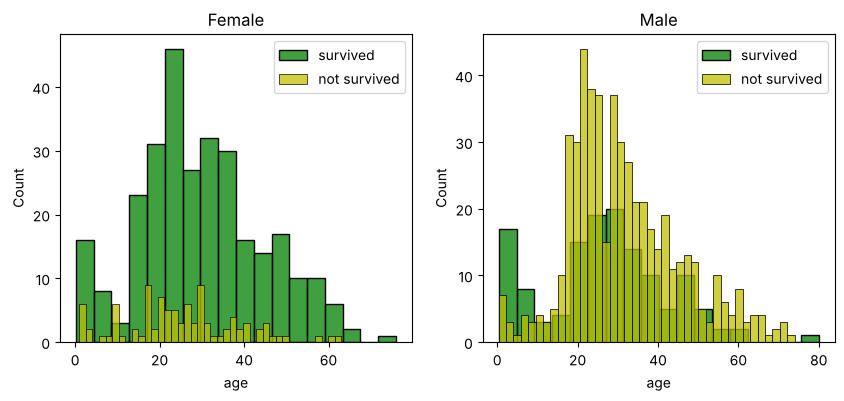

sex
female    0.727468
male      0.190985
Name: survived, dtype: float64
Nhận xét:
- Nam có xác suất sống sót cao ở độ tuổi 1 đến 10 (trẻ em).
- Nữ có cơ hội sống sót cao hơn trong khoảng 12 đến 40 tuổi.
- Nam không sống sót nhiều nhất ở độ tuổi 18 đến 27.
- Nhìn chung tỉ lệ sống của nữ (~73%) cao hơn hẳn nam (~19%) ở mọi lứa tuổi.


In [3]:
# ===== Câu 3: Liên quan giữa age, sex và survived =====
print("Nguyễn Bình Minh - 6451071047")

survived = 'survived'
not_survived = 'not survived'
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']
ax = sns.histplot(women[women['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[0], kde=False, color='g')
ax = sns.histplot(women[women['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[0], kde=False, color='y')
ax.legend()
ax.set_title('Female')
ax = sns.histplot(men[men['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[1], kde=False, color='g')
ax = sns.histplot(men[men['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[1], kde=False, color='y')
ax.legend()
ax.set_title('Male')
plt.show()
print(df.groupby('sex')['survived'].mean())

print('Nhận xét:')
print('- Nam có xác suất sống sót cao ở độ tuổi 1 đến 10 (trẻ em).')
print('- Nữ có cơ hội sống sót cao hơn trong khoảng 12 đến 40 tuổi.')
print('- Nam không sống sót nhiều nhất ở độ tuổi 18 đến 27.')
print('- Nhìn chung tỉ lệ sống của nữ (~73%) cao hơn hẳn nam (~19%) ở mọi lứa tuổi.')

Nguyễn Bình Minh - 6451071047


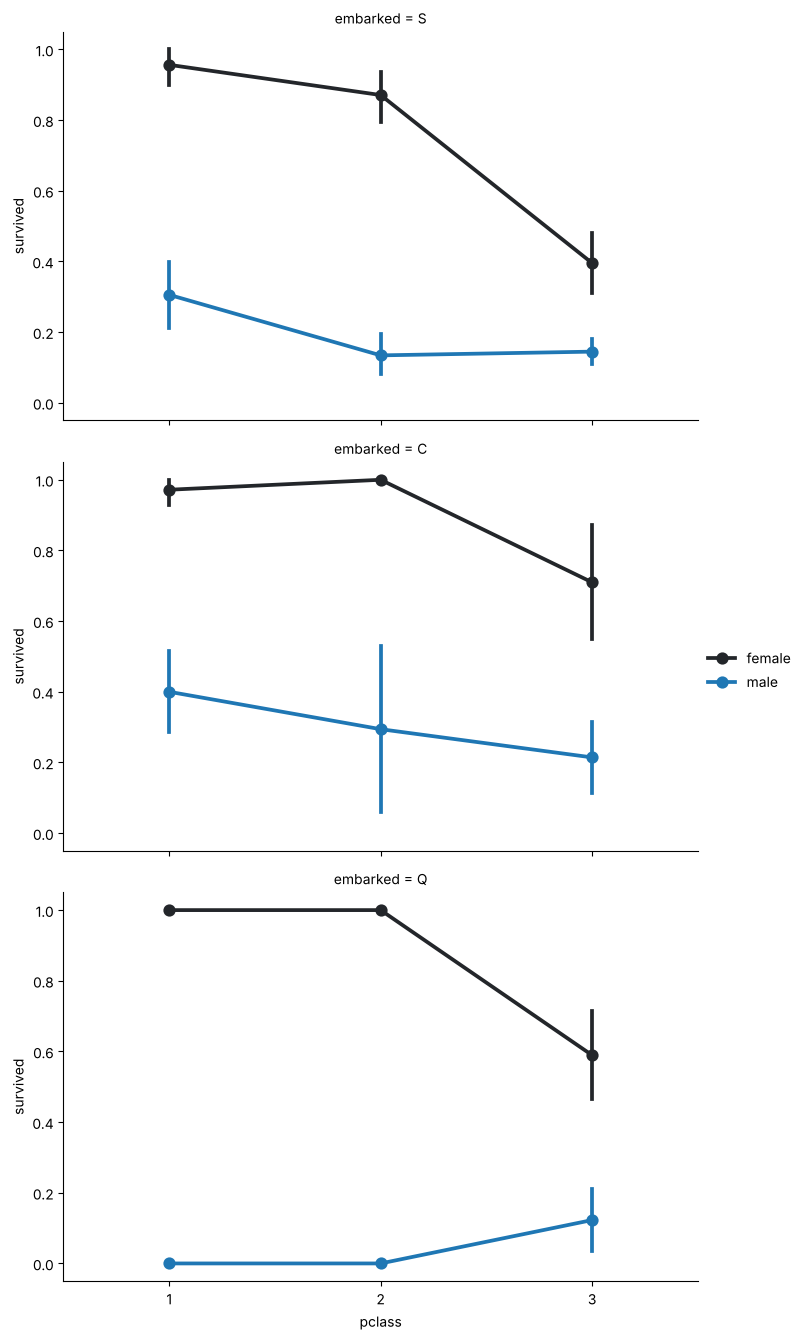

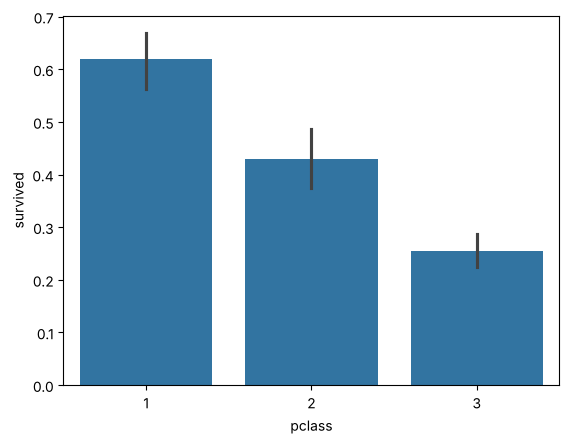

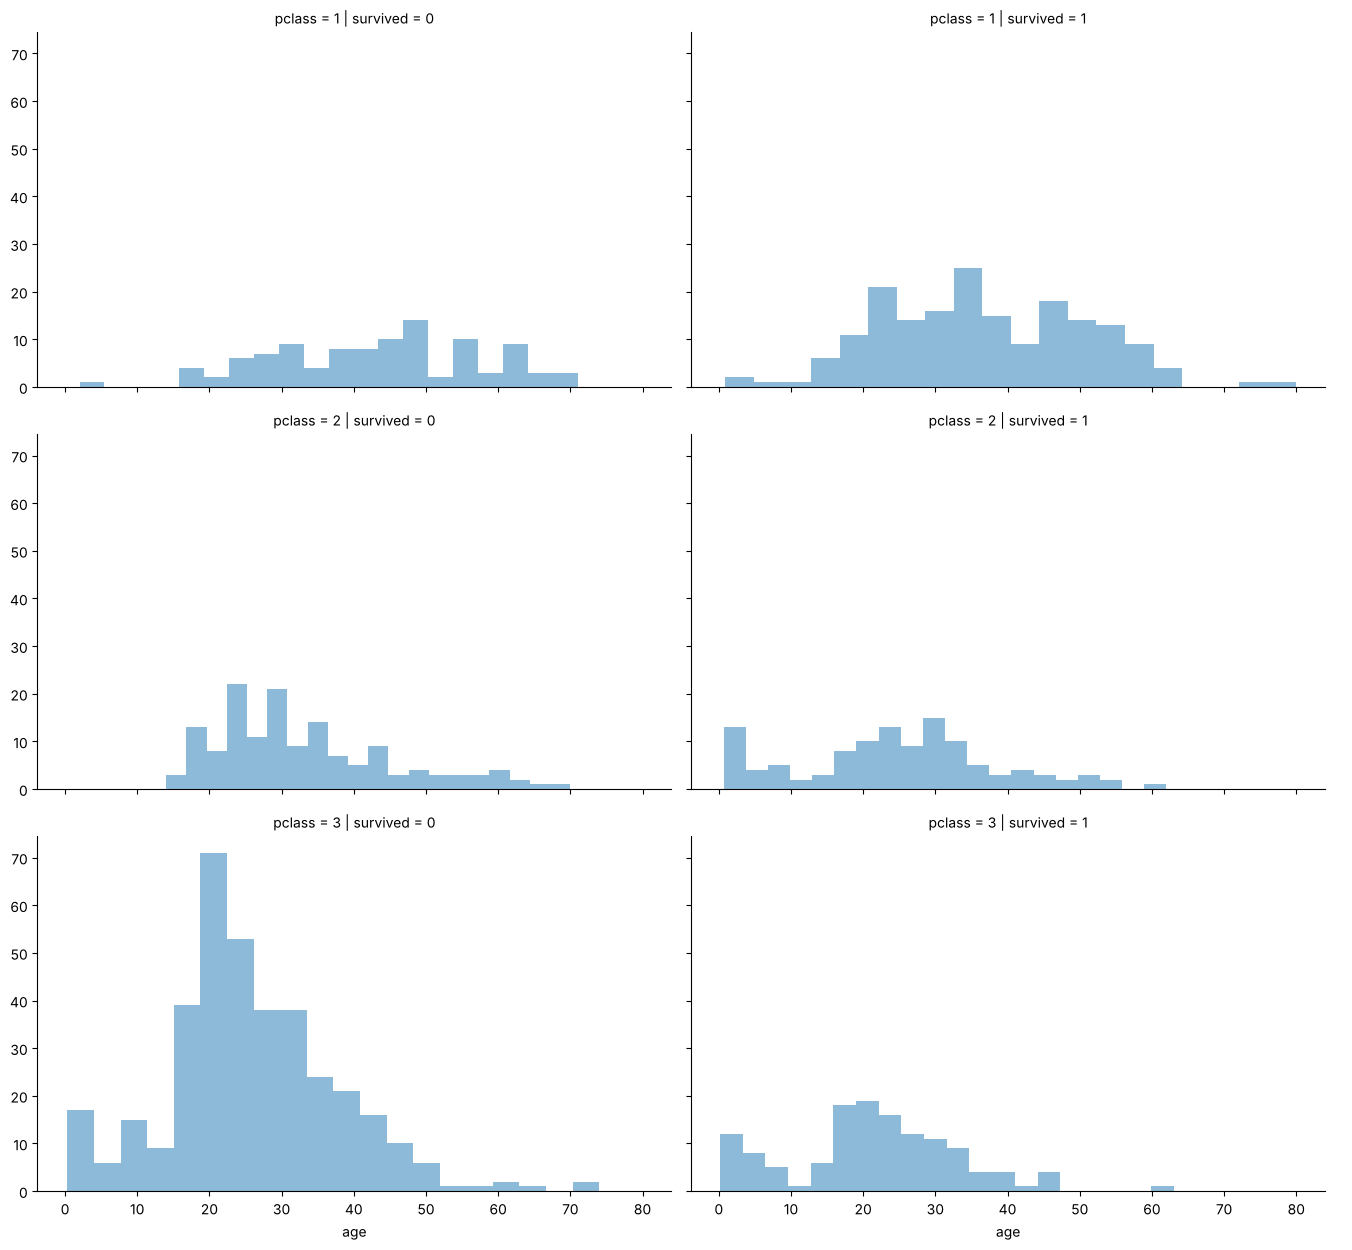

Nhận xét:
- Ở cả 3 cổng, nữ luôn có tỉ lệ sống sót cao hơn hẳn nam.
- Nữ vé hạng 1, 2 sống gần như 100%; vé hạng 3 thì nữ ở cổng C (~71%) và Q (~59%) sống nhiều hơn cổng S (~40%).
- Nam lên tàu ở cổng C có tỉ lệ sống cao nhất; nam ở cổng Q vé hạng 1, 2 không ai sống sót.
- Vé hạng 1 có tỉ lệ sống sót cao nhất (~62%), vé hạng 3 thấp nhất (~26%) và có rất nhiều người tử vong.


In [4]:
# ===== Câu 4: Liên quan giữa embarked, pclass với survived, phân biệt theo sex =====
print("Nguyễn Bình Minh - 6451071047")

FacetGrid = sns.FacetGrid(df, row='embarked', height=4.5, aspect=1.6)
FacetGrid.map(sns.pointplot, 'pclass', 'survived', 'sex', palette=None,
              order=[1, 2, 3], hue_order=['female', 'male'])
FacetGrid.add_legend()
plt.show()

sns.barplot(x='pclass', y='survived', data=df)
plt.show()

grid = sns.FacetGrid(df, col='survived', row='pclass', height=4.2, aspect=1.6)
grid.map(plt.hist, 'age', alpha=.5, bins=20)
grid.add_legend()
plt.show()

print('Nhận xét:')
print('- Ở cả 3 cổng, nữ luôn có tỉ lệ sống sót cao hơn hẳn nam.')
print('- Nữ vé hạng 1, 2 sống gần như 100%; vé hạng 3 thì nữ ở cổng C (~71%) và Q (~59%) sống nhiều hơn cổng S (~40%).')
print('- Nam lên tàu ở cổng C có tỉ lệ sống cao nhất; nam ở cổng Q vé hạng 1, 2 không ai sống sót.')
print('- Vé hạng 1 có tỉ lệ sống sót cao nhất (~62%), vé hạng 3 thấp nhất (~26%) và có rất nhiều người tử vong.')

Nguyễn Bình Minh - 6451071047
not_alone
1    790
0    519
Name: count, dtype: int64


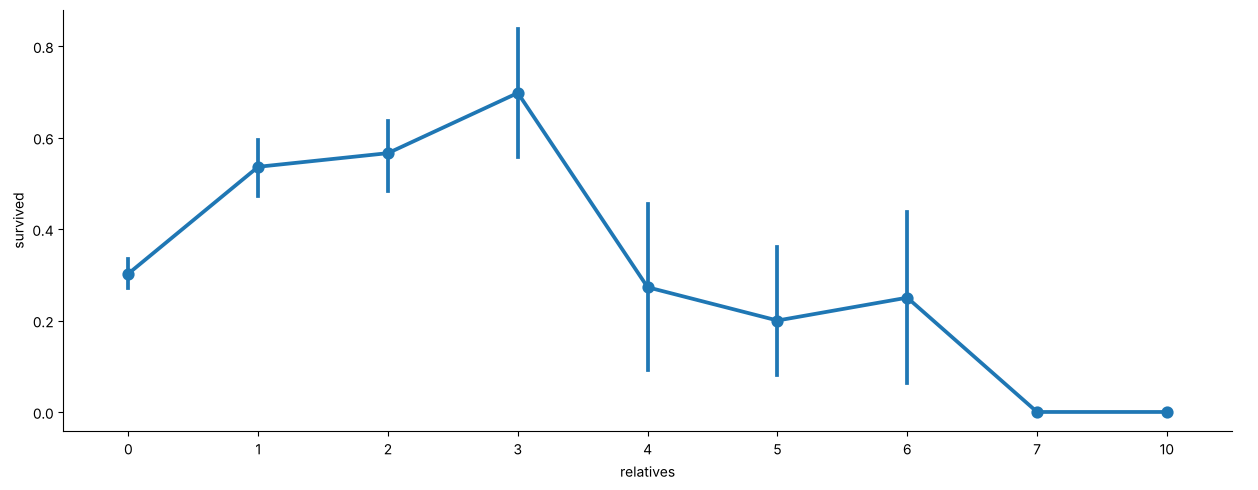

Nhận xét:
- Số người đi một mình (not_alone = 1) là 790, đi cùng người thân (not_alone = 0) là 519.
- Người có 1 đến 3 người thân đi cùng có tỉ lệ sống sót cao hơn (cao nhất khi có 3 người thân).
- Người đi một mình có tỉ lệ sống khoảng 30%; người có 7 đến 10 người thân có tỉ lệ sống thấp nhất (gần 0).


In [5]:
# ===== Câu 5: Thống kê số người đi cùng và liên quan với survived =====
print("Nguyễn Bình Minh - 6451071047")

for dataset in [df]:
    dataset['relatives'] = dataset['sibsp'] + dataset['parch']
    dataset.loc[dataset['relatives'] > 0, 'not_alone'] = 0
    dataset.loc[dataset['relatives'] == 0, 'not_alone'] = 1
    dataset['not_alone'] = dataset['not_alone'].astype(int)

print(df['not_alone'].value_counts())

sns.catplot(x='relatives', y='survived', data=df, aspect=2.5, kind='point')
plt.show()

print('Nhận xét:')
print('- Số người đi một mình (not_alone = 1) là 790, đi cùng người thân (not_alone = 0) là 519.')
print('- Người có 1 đến 3 người thân đi cùng có tỉ lệ sống sót cao hơn (cao nhất khi có 3 người thân).')
print('- Người đi một mình có tỉ lệ sống khoảng 30%; người có 7 đến 10 người thân có tỉ lệ sống thấp nhất (gần 0).')

In [6]:
# ===== Câu 6: Tiền xử lý thuộc tính thiếu dữ liệu và xóa thuộc tính không cần thiết =====
print("Nguyễn Bình Minh - 6451071047")

# Tách deck (boong tàu) từ cabin trước khi xóa cabin

deck = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}

for dataset in [df]:
    dataset['cabin'] = dataset['cabin'].fillna("U0")
    dataset['deck'] = dataset['cabin'].map(lambda x: re.compile("([a-zA-Z]+)").search(x).group())
    dataset['deck'] = dataset['deck'].map(deck)
    dataset['deck'] = dataset['deck'].fillna(0)
    dataset['deck'] = dataset['deck'].astype(int)
# we can now drop the cabin feature
df = df.drop(['cabin'], axis=1)

# ticket có quá nhiều giá trị khác nhau -> không hữu ích
print(df['ticket'].describe(), '\n')

df = df.drop(['ticket'], axis=1)
df = df.drop(['boat'], axis=1)
df = df.drop(['body'], axis=1)
df = df.drop(['home.dest'], axis=1)

# Điền age bằng số ngẫu nhiên trong [mean - std, mean + std]

np.random.seed(42)   # cố định để kết quả chạy lại giống nhau
for dataset in [df]:
    mean = df["age"].mean()
    std = df["age"].std()
    is_null = dataset["age"].isnull().sum()
    # compute random numbers between the mean, std and is_null
    rand_age = np.random.randint(mean - std, mean + std, size=is_null)
    # fill NaN values in Age column with random values generated
    age_slice = dataset["age"].copy()
    age_slice[np.isnan(age_slice)] = rand_age
    dataset["age"] = age_slice
    dataset["age"] = df["age"].astype(int)


# Điền embarked bằng giá trị phổ biến nhất
print(df['embarked'].describe(), '\n')

common_value = 'S'
for dataset in [df]:
    dataset['embarked'] = dataset['embarked'].fillna(common_value)

df.info()
print(df.isnull().sum())

Nguyễn Bình Minh - 6451071047
count         1309
unique         929
top       CA. 2343
freq            11
Name: ticket, dtype: object 

count     1307
unique       3
top          S
freq       914
Name: embarked, dtype: object 

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1309 non-null   int64  
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   fare       1308 non-null   float64
 8   embarked   1309 non-null   str    
 9   relatives  1309 non-null   int64  
 10  not_alone  1309 non-null   int64  
 11  deck       1309 non-null   int64  
dtypes: float64(1), int64(8), str(3)
memory usage: 122.8 KB
pclass       0
survived     0
name         0
sex        

In [7]:
# ===== Câu 7: Biến đổi các thuộc tính =====
print("Nguyễn Bình Minh - 6451071047")

# a) fare về kiểu nguyên

for dataset in [df]:
    dataset['fare'] = dataset['fare'].fillna(0)
    dataset['fare'] = dataset['fare'].astype(int)

# b) Trích xuất title từ name

titles = {"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}

for dataset in [df]:
    # extract titles
    dataset['title'] = dataset.name.str.extract(r' ([A-Za-z]+)\.', expand=False)
    # replace titles with a more common title or as Rare
    dataset['title'] = dataset['title'].replace(['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr',
                                                 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
    dataset['title'] = dataset['title'].replace('Mlle', 'Miss')
    dataset['title'] = dataset['title'].replace('Ms', 'Miss')
    dataset['title'] = dataset['title'].replace('Mme', 'Mrs')
    # convert titles into numbers
    dataset['title'] = dataset['title'].map(titles)
    # filling NaN with 0, to get safe
    dataset['title'] = dataset['title'].fillna(0).astype(int)
df = df.drop(['name'], axis=1)

print(df['title'].value_counts(), '\n')

# c) sex và embarked thành số

genders = {"male": 0, "female": 1}
for dataset in [df]:
    dataset['sex'] = dataset['sex'].map(genders)

ports = {"S": 0, "C": 1, "Q": 2}
for dataset in [df]:
    dataset['embarked'] = dataset['embarked'].map(ports)

# d) Chia age thành 8 nhóm

for dataset in [df]:
    dataset['age'] = dataset['age'].astype(int)
    dataset.loc[ dataset['age'] <= 11, 'age'] = 0
    dataset.loc[(dataset['age'] > 11) & (dataset['age'] <= 18), 'age'] = 1
    dataset.loc[(dataset['age'] > 18) & (dataset['age'] <= 22), 'age'] = 2
    dataset.loc[(dataset['age'] > 22) & (dataset['age'] <= 27), 'age'] = 3
    dataset.loc[(dataset['age'] > 27) & (dataset['age'] <= 33), 'age'] = 4
    dataset.loc[(dataset['age'] > 33) & (dataset['age'] <= 40), 'age'] = 5
    dataset.loc[(dataset['age'] > 40) & (dataset['age'] <= 66), 'age'] = 6
    dataset.loc[ dataset['age'] > 66, 'age'] = 7

print(df['age'].value_counts(), '\n')

# e) Chia fare thành 6 nhóm

for dataset in [df]:
    dataset.loc[ dataset['fare'] <= 7.91, 'fare'] = 0
    dataset.loc[(dataset['fare'] > 7.91) & (dataset['fare'] <= 14.454), 'fare'] = 1
    dataset.loc[(dataset['fare'] > 14.454) & (dataset['fare'] <= 31), 'fare'] = 2
    dataset.loc[(dataset['fare'] > 31) & (dataset['fare'] <= 99), 'fare'] = 3
    dataset.loc[(dataset['fare'] > 99) & (dataset['fare'] <= 250), 'fare'] = 4
    dataset.loc[ dataset['fare'] > 250, 'fare'] = 5
    dataset['fare'] = dataset['fare'].astype(int)

print(df['fare'].value_counts())
display(df.head(10))

Nguyễn Bình Minh - 6451071047
title
1    757
2    264
3    198
4     61
5     29
Name: count, dtype: int64 

age
6    249
4    224
3    214
5    202
2    176
1    144
0     91
7      9
Name: count, dtype: int64 

fare
0    361
2    325
1    312
3    227
4     67
5     17
Name: count, dtype: int64


,pclass,survived,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck,title
0,1,1,1,4,0,0,4,0,0,1,2,2
1,1,1,0,0,1,2,4,0,3,0,3,4
2,1,0,1,0,1,2,4,0,3,0,3,2
3,1,0,0,4,1,2,4,0,3,0,3,1
4,1,0,1,3,1,2,4,0,3,0,3,3
5,1,1,0,6,0,0,2,0,0,1,5,1
6,1,1,1,6,1,0,3,0,1,0,4,2
7,1,0,0,5,0,0,0,0,0,1,1,1
8,1,1,1,6,2,0,3,0,2,0,3,3
9,1,0,0,7,0,0,3,1,0,1,8,1


In [8]:
# ===== Câu 8: Tạo các thuộc tính mới =====
print("Nguyễn Bình Minh - 6451071047")

# Thuộc tính tuổi * loại vé
for dataset in [df]:
    dataset['age_class'] = dataset['age'] * dataset['pclass']

# Thuộc tính giá vé trên mỗi người
for dataset in [df]:
    dataset['fare_per_person'] = dataset['fare'] / (dataset['relatives'] + 1)
    dataset['fare_per_person'] = dataset['fare_per_person'].astype(int)

display(df.head(10))

Nguyễn Bình Minh - 6451071047


,pclass,survived,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck,title,age_class,fare_per_person
0,1,1,1,4,0,0,4,0,0,1,2,2,4,4
1,1,1,0,0,1,2,4,0,3,0,3,4,0,1
2,1,0,1,0,1,2,4,0,3,0,3,2,0,1
3,1,0,0,4,1,2,4,0,3,0,3,1,4,1
4,1,0,1,3,1,2,4,0,3,0,3,3,3,1
5,1,1,0,6,0,0,2,0,0,1,5,1,6,2
6,1,1,1,6,1,0,3,0,1,0,4,2,6,1
7,1,0,0,5,0,0,0,0,0,1,1,1,5,0
8,1,1,1,6,2,0,3,0,2,0,3,3,6,1
9,1,0,0,7,0,0,3,1,0,1,8,1,7,3
